In [2]:
%pip install matplotlib pandas numpy pillow

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.3 MB 10.5 MB/s eta 0:00:01
   --------------- ------------------------ 3.7/9.3 MB 11.5 MB/s eta 0:00:01
   ------------------------------- -------- 7.3/9.3 MB 13.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 11.4 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   -------------- ------------------------- 2.6/7.3 MB 13.8 MB/s eta 0:00:01
   ------------------------ --------------- 4.5/7.3 MB 14.2 MB/s eta 0:00:01
   ------------------------------------- -- 6.8/7.3 MB 11.1 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 11.0 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? et

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
from pathlib import Path
from collections import Counter
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path(r"E:\PlantVillage\data\images")

random.seed(42)
np.random.seed(42)

print("Dataset directory exists:", DATA_DIR.exists())
print("Dataset path:", DATA_DIR)

Dataset directory exists: True
Dataset path: E:\PlantVillage\data\images


In [2]:
# Get all class folders
class_folders = sorted(
    folder for folder in DATA_DIR.iterdir()
    if folder.is_dir()
)

# Count images in each class
class_counts = {}

for folder in class_folders:
    image_files = [
        f for f in folder.iterdir()
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]
    class_counts[folder.name] = len(image_files)

# Create a sorted DataFrame
class_df = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Image_Count"]
).sort_values("Image_Count", ascending=False)

print("Number of classes:", len(class_df))
print("Total images:", class_df["Image_Count"].sum())
display(class_df)

Number of classes: 38
Total images: 54305


,Class,Image_Count
15,Orange___Haunglongbing_(Citrus_greening),5507
37,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
24,Soybean___healthy,5090
16,Peach___Bacterial_spot,2297
28,Tomato___Bacterial_spot,2127
31,Tomato___Late_blight,1909
25,Squash___Powdery_mildew,1835
33,Tomato___Septoria_leaf_spot,1771
34,Tomato___Spider_mites Two-spotted_spider_mite,1676
3,Apple___healthy,1645


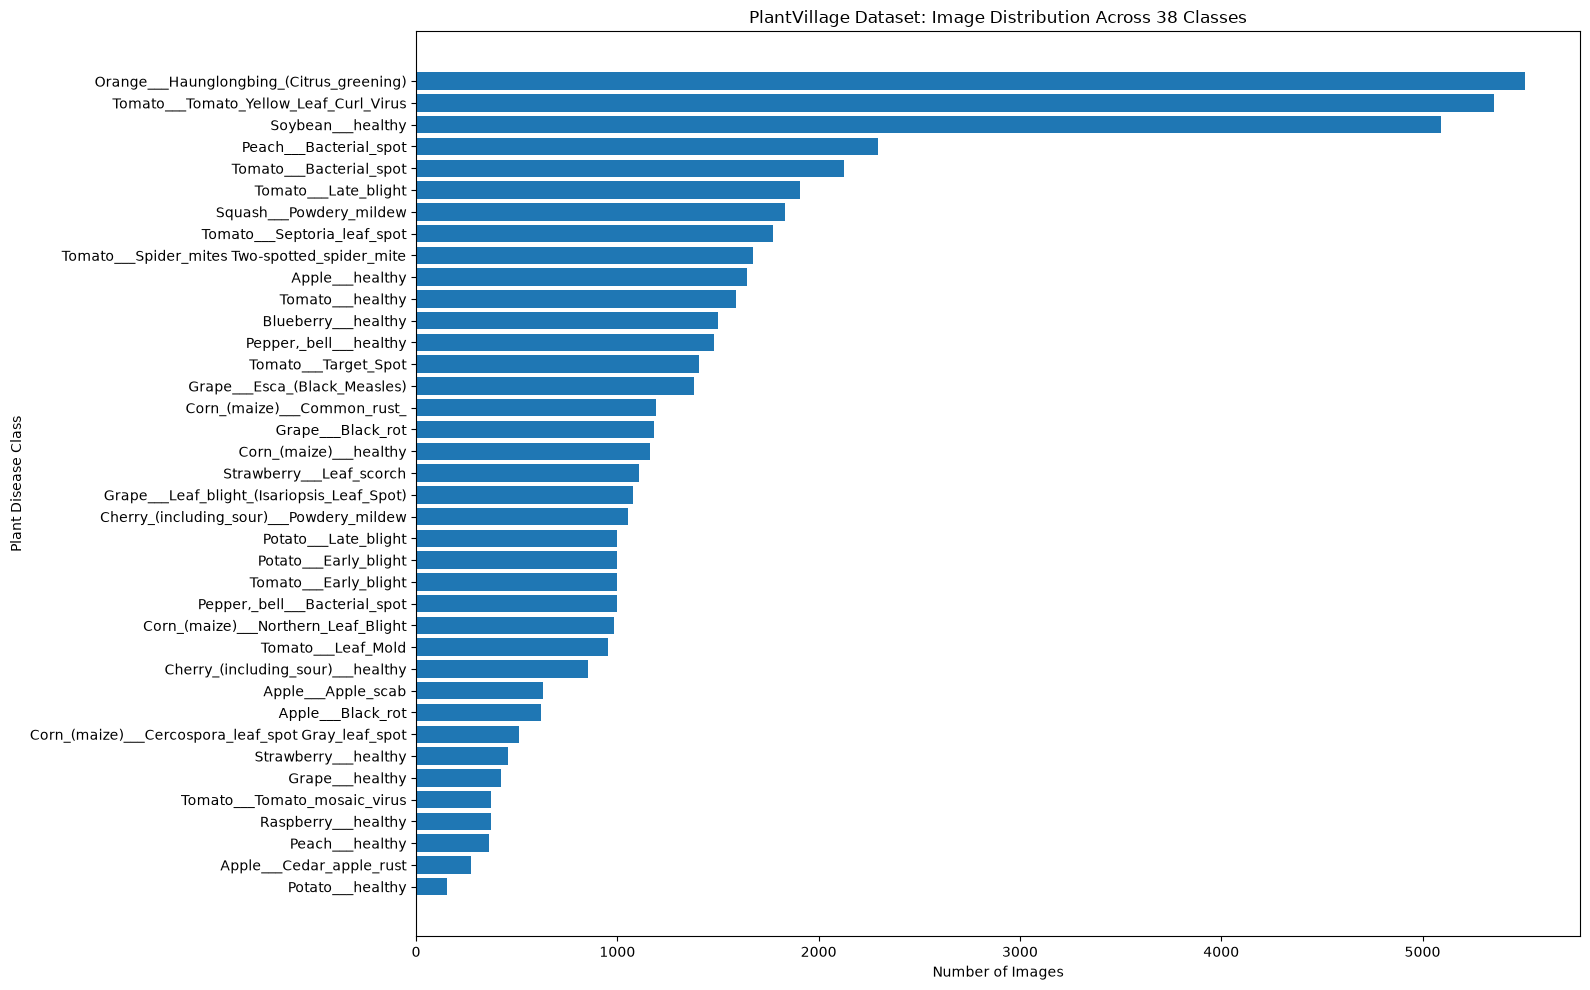

In [3]:
plt.figure(figsize=(16, 10))

plt.barh(
    class_df["Class"],
    class_df["Image_Count"]
)

plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Class")
plt.title("PlantVillage Dataset: Image Distribution Across 38 Classes")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

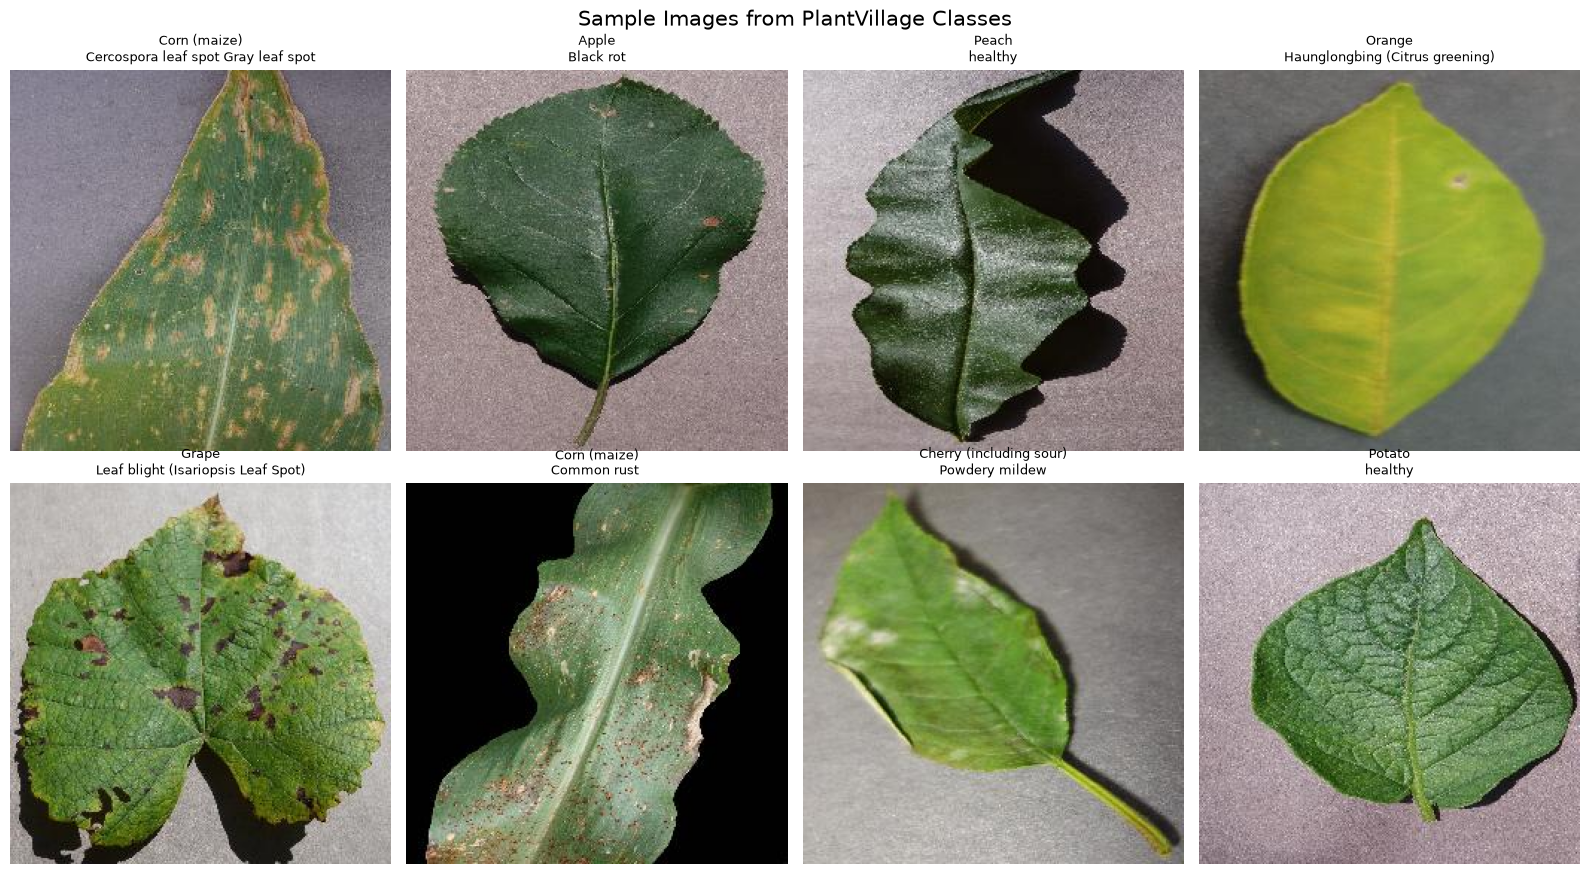

In [4]:
random.seed(42)

sample_classes = random.sample(class_folders, 8)

fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for ax, class_folder in zip(axes.flat, sample_classes):
    image_files = [
        f for f in class_folder.iterdir()
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    label = class_folder.name.replace("___", "\n").replace("_", " ")
    ax.set_title(label, fontsize=9)
    ax.axis("off")

plt.suptitle("Sample Images from PlantVillage Classes", fontsize=15)
plt.tight_layout()
plt.show()

In [5]:
from collections import Counter
from PIL import Image

image_extensions = {".jpg", ".jpeg", ".png"}
image_sizes = Counter()
total_images = 0
unreadable_images = []

for class_folder in class_folders:
    for image_path in class_folder.iterdir():
        if image_path.suffix.lower() not in image_extensions:
            continue

        try:
            with Image.open(image_path) as img:
                image_sizes[img.size] += 1
                total_images += 1
        except Exception:
            unreadable_images.append(str(image_path))

print("Total images checked:", total_images)
print("Number of unique image dimensions:", len(image_sizes))
print("\nMost common dimensions (width, height):")

for size, count in image_sizes.most_common(10):
    print(f"{size}: {count} images")

print("\nUnreadable images:", len(unreadable_images))

Total images checked: 54305
Number of unique image dimensions: 1

Most common dimensions (width, height):
(256, 256): 54305 images

Unreadable images: 0


In [6]:
from collections import Counter
from PIL import Image

mode_counts = Counter()
sample_pixels = []

for class_folder in class_folders:
    image_files = [
        f for f in class_folder.iterdir()
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    for image_path in image_files:
        with Image.open(image_path) as img:
            mode_counts[img.mode] += 1

        if len(sample_pixels) < 100:
            with Image.open(image_path) as img:
                rgb_img = img.convert("RGB")
                sample_pixels.append(
                    np.asarray(rgb_img, dtype=np.float32) / 255.0
                )

print("Image color modes:")
for mode, count in mode_counts.items():
    print(f"{mode}: {count}")

sample_pixels = np.concatenate(
    [img.reshape(-1, 3) for img in sample_pixels],
    axis=0
)

print("\nSample RGB channel statistics:")
print("Mean RGB:", sample_pixels.mean(axis=0))
print("Std RGB:", sample_pixels.std(axis=0))

Image color modes:
RGB: 54304
RGBA: 1

Sample RGB channel statistics:
Mean RGB: [0.39961436 0.4457003  0.41393468]
Std RGB: [0.17804192 0.15221174 0.21381292]


In [7]:
import hashlib
from collections import defaultdict

hash_to_paths = defaultdict(list)

for class_folder in class_folders:
    for image_path in class_folder.iterdir():
        if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        hasher = hashlib.md5()

        with open(image_path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                hasher.update(chunk)

        hash_to_paths[hasher.hexdigest()].append(image_path)

duplicate_groups = {
    file_hash: paths
    for file_hash, paths in hash_to_paths.items()
    if len(paths) > 1
}

print("Unique file hashes:", len(hash_to_paths))
print("Exact duplicate groups:", len(duplicate_groups))

if duplicate_groups:
    print("\nExamples:")
    for paths in list(duplicate_groups.values())[:5]:
        print([str(p) for p in paths])

Unique file hashes: 54284
Exact duplicate groups: 21

Examples:
['E:\\PlantVillage\\data\\images\\Apple___healthy\\11beda66-01e9-4bfd-be37-c0f8646d1478___RS_HL 6271.JPG', 'E:\\PlantVillage\\data\\images\\Apple___healthy\\13298d36-4425-437d-ae8e-c7d70e200084___RS_HL 6271.JPG']
['E:\\PlantVillage\\data\\images\\Apple___healthy\\14896dc0-688d-456f-b5ec-a037695b0193___RS_HL 6268.JPG', 'E:\\PlantVillage\\data\\images\\Apple___healthy\\c21cf428-bfc3-4710-b5d2-69d1c0e94748___RS_HL 6268.JPG']
['E:\\PlantVillage\\data\\images\\Apple___healthy\\1ab5e019-e5f0-4d8e-a252-94cb0aab8b0a___RS_HL 6269.JPG', 'E:\\PlantVillage\\data\\images\\Apple___healthy\\3673d121-b5de-481c-b057-d4ee5b4959b1___RS_HL 6269.JPG']
['E:\\PlantVillage\\data\\images\\Apple___healthy\\3d075f90-7002-4c45-abc0-4f35ee49aa79___RS_HL 6272.JPG', 'E:\\PlantVillage\\data\\images\\Apple___healthy\\acb21cc2-8d65-4880-a7bb-dcc1eab1564b___RS_HL 6272.JPG']
['E:\\PlantVillage\\data\\images\\Apple___healthy\\5192db55-4aa7-421c-92d4-c2dac79e7

In [9]:
from pathlib import Path
from collections import defaultdict
import hashlib

DATA_DIR = Path(r"E:\PlantVillage\data\images")
METADATA_DIR = Path(r"E:\PlantVillage\data\metadata")

def load_split(filename):
    split_file = METADATA_DIR / "splits" / filename
    with open(split_file, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

def local_image_path(official_path):
    parts = Path(official_path).parts
    return DATA_DIR.joinpath(*parts[2:])

train_paths = load_split("color_train.txt")
test_paths = load_split("color_test.txt")

train_local = [local_image_path(p) for p in train_paths]
test_local = [local_image_path(p) for p in test_paths]

print("Training images:", len(train_local))
print("Test images:", len(test_local))
print("Missing training images:", sum(not p.is_file() for p in train_local))
print("Missing test images:", sum(not p.is_file() for p in test_local))

Training images: 43596
Test images: 10709
Missing training images: 0
Missing test images: 0


In [10]:
import hashlib
from collections import defaultdict

def get_md5(path):
    hasher = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

train_hashes = defaultdict(list)
test_hashes = defaultdict(list)

# Hash official training images
for path in train_local:
    train_hashes[get_md5(path)].append(path)

# Hash official test images
for path in test_local:
    test_hashes[get_md5(path)].append(path)

cross_split_hashes = set(train_hashes) & set(test_hashes)

print("Unique hashes in training:", len(train_hashes))
print("Unique hashes in test:", len(test_hashes))
print("Exact duplicate hashes shared across train/test:", len(cross_split_hashes))

if cross_split_hashes:
    print("\nExamples:")
    for file_hash in list(cross_split_hashes)[:5]:
        print("TRAIN:", train_hashes[file_hash][0])
        print("TEST: ", test_hashes[file_hash][0])

Unique hashes in training: 43582
Unique hashes in test: 10707
Exact duplicate hashes shared across train/test: 5

Examples:
TRAIN: E:\PlantVillage\data\images\Tomato___healthy\9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG
TEST:  E:\PlantVillage\data\images\Tomato___healthy\d2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL Leaf 220.JPG
TRAIN: E:\PlantVillage\data\images\Tomato___healthy\34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL Leaf 466.1.JPG
TEST:  E:\PlantVillage\data\images\Tomato___healthy\068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL Leaf 466.1.JPG
TRAIN: E:\PlantVillage\data\images\Tomato___Late_blight\3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg
TEST:  E:\PlantVillage\data\images\Tomato___Late_blight\5de6da85-f8c4-48c4-b463-3e6bd78884cc___GHLB_PS Leaf 24 Day 16.jpg
TRAIN: E:\PlantVillage\data\images\Tomato___Late_blight\e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 Leaf 8999.JPG
TEST:  E:\PlantVillage\data\images\Tomato___Late_blight\5f21282c-e2ef-4c4

In [11]:
print("Exact duplicate groups across train/test:", len(cross_split_hashes))

for file_hash in sorted(cross_split_hashes):
    train_path = train_hashes[file_hash][0]
    test_path = test_hashes[file_hash][0]

    train_label = train_path.parent.name
    test_label = test_path.parent.name

    print("\nTrain label:", train_label)
    print("Test label: ", test_label)
    print("Same class: ", train_label == test_label)
    print("Train file: ", train_path.name)
    print("Test file:  ", test_path.name)

Exact duplicate groups across train/test: 5

Train label: Tomato___Late_blight
Test label:  Tomato___Late_blight
Same class:  True
Train file:  e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 Leaf 8999.JPG
Test file:   5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 Leaf 8999.JPG

Train label: Tomato___healthy
Test label:  Tomato___healthy
Same class:  True
Train file:  34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL Leaf 466.1.JPG
Test file:   068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL Leaf 466.1.JPG

Train label: Tomato___Late_blight
Test label:  Tomato___Late_blight
Same class:  True
Train file:  48c55974-9fe9-4f4b-94f7-c8cd127d1e05___GHLB_PS Leaf 23.7 Day 13.jpg
Test file:   bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f1b___GHLB_PS Leaf 23.7 Day 13.jpg

Train label: Tomato___healthy
Test label:  Tomato___healthy
Same class:  True
Train file:  9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG
Test file:   d2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL Leaf 220.JPG

Train label: Tomato___Late_bl

In [12]:
affected_train = sum(
    len(train_hashes[h]) for h in cross_split_hashes
)
affected_test = sum(
    len(test_hashes[h]) for h in cross_split_hashes
)

print("Shared exact duplicate hashes:", len(cross_split_hashes))
print("Affected training files:", affected_train)
print("Affected test files:", affected_test)

Shared exact duplicate hashes: 5
Affected training files: 5
Affected test files: 5
